<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Experiment 25: Restricted Boltzmann Machine Energy and Reconstruction

This notebook implements a Restricted Boltzmann Machine (RBM) with 784 visible units and 64 hidden units to learn hidden patterns and reconstruct inputs.

### Task 1: RBM Energy Function

We define the RBM energy function:
$$E(v, h) = -a^T v - b^T h - v^T W h$$

Where:
* $v$ is the visible vector.
* $h$ is the hidden vector.
* $a$ is the visible bias vector.
* $b$ is the hidden bias vector.
* $W$ is the weight matrix.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def energy_function(v, h, W, a, b):
    """
    Computes the energy of a configuration (v, h).
    v: visible state vector or batch of vectors (shape: [batch_size, n_visible])
    h: hidden state vector or batch of vectors (shape: [batch_size, n_hidden])
    """
    # Ensure 2D arrays
    if v.ndim == 1:
        v = v.reshape(1, -1)
    if h.ndim == 1:
        h = h.reshape(1, -1)

    term_v = np.dot(v, a)
    term_h = np.dot(h, b)
    term_W = np.sum(np.dot(v, W) * h, axis=1)

    return - (term_v + term_h + term_W)

### Task 2: Conditional Probabilities and Free Energy

We define functions to compute the conditional activation probabilities:
* $p(h_j = 1 | v) = \sigma(b_j + \sum_i v_i W_{ij})$
* $p(v_i = 1 | h) = \sigma(a_i + \sum_j h_j W_{ij})$

We also implement the free energy function, which is analytical and used to track convergence:
$$F(v) = -a^T v - \sum_j \log(1 + e^{b_j + v^T W_{*, j}})$$

In [2]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

def sample_h_given_v(v, W, b):
    h_prob = sigmoid(np.dot(v, W) + b)
    h_sample = (h_prob > np.random.rand(*h_prob.shape)).astype(np.float32)
    return h_prob, h_sample

def sample_v_given_h(h, W, a):
    v_prob = sigmoid(np.dot(h, W.T) + a)
    v_sample = (v_prob > np.random.rand(*v_prob.shape)).astype(np.float32)
    return v_prob, v_sample

def free_energy(v, W, a, b):
    term_v = np.dot(v, a)
    activation = np.dot(v, W) + b
    term_h = np.sum(np.log(1.0 + np.exp(np.clip(activation, -500, 500))), axis=1)
    return - (term_v + term_h)

### Task 3: One-Step Contrastive Divergence (CD-1)

We implement the Contrastive Divergence training step and the model initialization.

In [3]:
class RBM:
    def __init__(self, n_visible=784, n_hidden=64, lr=0.1):
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.lr = lr
        # Initialize weights and biases
        self.W = np.random.normal(0, 0.01, (n_visible, n_hidden))
        self.a = np.zeros(n_visible)
        self.b = np.zeros(n_hidden)

    def train_step(self, v0):
        # Positive phase
        h0_prob, h0_sample = sample_h_given_v(v0, self.W, self.b)

        # Negative phase (one-step reconstruction)
        v1_prob, v1_sample = sample_v_given_h(h0_sample, self.W, self.a)
        h1_prob, _ = sample_h_given_v(v1_sample, self.W, self.b)

        # Gradients
        w_grad = np.dot(v0.T, h0_prob) - np.dot(v1_sample.T, h1_prob)
        a_grad = np.sum(v0 - v1_sample, axis=0)
        b_grad = np.sum(h0_prob - h1_prob, axis=0)

        # Update parameters
        batch_size = v0.shape[0]
        self.W += self.lr * (w_grad / batch_size)
        self.a += self.lr * (a_grad / batch_size)
        self.b += self.lr * (b_grad / batch_size)

        # Reconstruction error
        recon_err = np.mean((v0 - v1_prob) ** 2)
        return recon_err

### Task 4: Training and Tracking Free Energy / Reconstruction Error

We generate synthetic binary dataset (similar to binarized MNIST digits) and train our RBM.

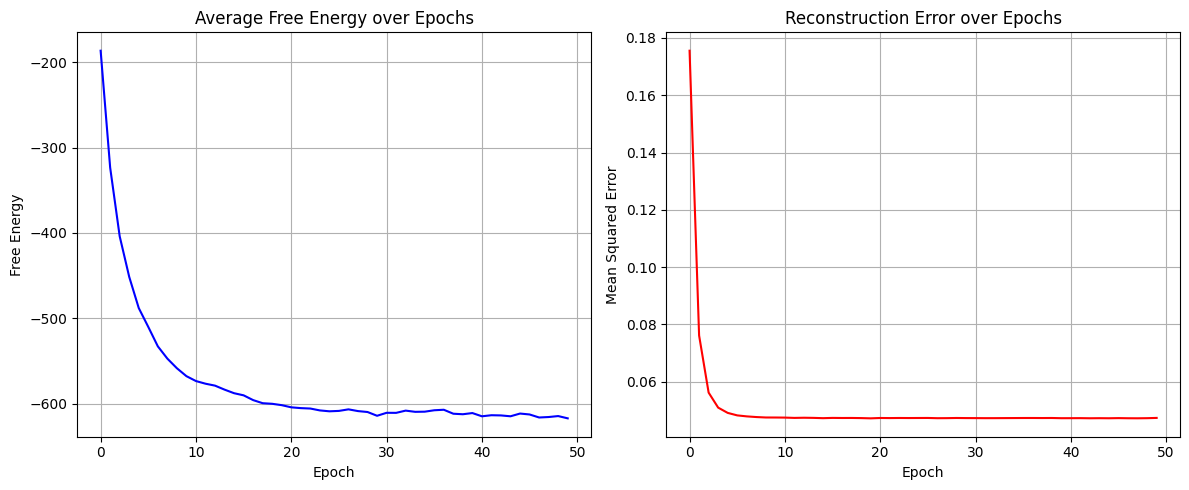

In [4]:
# Generate synthetic dataset
np.random.seed(42)
n_samples = 500
patterns = np.random.binomial(1, 0.3, (5, 784))
data = np.array([patterns[np.random.choice(5)] ^ np.random.binomial(1, 0.05, 784) for _ in range(n_samples)]).astype(np.float32)

rbm = RBM(n_visible=784, n_hidden=64, lr=0.1)
epochs = 50
batch_size = 32

epoch_free_energy = []
epoch_recon_error = []

for epoch in range(epochs):
    np.random.shuffle(data)
    batch_errors = []
    for i in range(0, n_samples, batch_size):
        batch = data[i:i+batch_size]
        err = rbm.train_step(batch)
        batch_errors.append(err)

    # Tracking average metrics
    mean_free_energy = np.mean(free_energy(data, rbm.W, rbm.a, rbm.b))
    epoch_free_energy.append(mean_free_energy)
    epoch_recon_error.append(np.mean(batch_errors))

# Plotting Metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epoch_free_energy, color='blue', label='Free Energy')
ax1.set_title('Average Free Energy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Free Energy')
ax1.grid(True)

ax2.plot(epoch_recon_error, color='red', label='Reconstruction Error')
ax2.set_title('Reconstruction Error over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Mean Squared Error')
ax2.grid(True)

plt.tight_layout()
plt.show()

### Task 5: Showing Original and Reconstructed Samples

We visually contrast the original input samples with their respective reconstructions generated by the model.

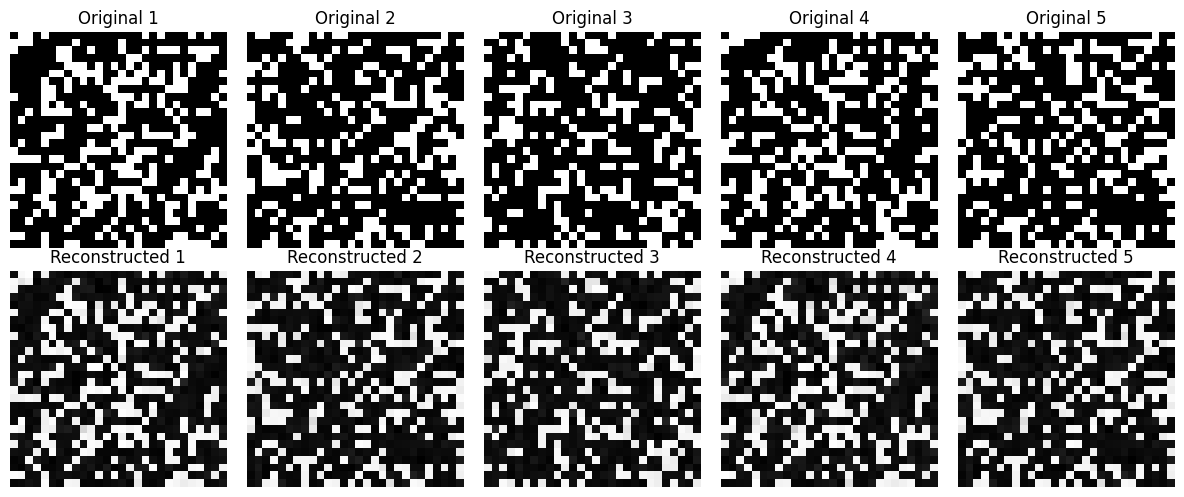

In [5]:
test_samples = data[:5]
_, h_samples = sample_h_given_v(test_samples, rbm.W, rbm.b)
recon_samples, _ = sample_v_given_h(h_samples, rbm.W, rbm.a)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    # Original
    axes[0, i].imshow(test_samples[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_title(f"Original {i+1}")
    axes[0, i].axis('off')

    # Reconstruction
    axes[1, i].imshow(recon_samples[i].reshape(28, 28), cmap='gray')
    axes[1, i].set_title(f"Reconstructed {i+1}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()